# Number theory 7: The number field sieve

*Learning path: number theory, part 7 of 7.* [Index](README.md) · Previous: [The factoring lab](06-factoring-lab.ipynb)

Every record factorization since the 1990s, up to RSA-250 (250 digits, in 2020), was done with the **number field
sieve**. It is famous for being hard to understand. This lesson builds it from small pieces you can check by hand,
and only then runs the real thing.

**Who this is for.** You have done the earlier lessons of this path, or you know the same material from elsewhere:

* `mod` and `gcd`, and what $a \equiv b \pmod n$ means ([lesson 4](04-modular-arithmetic.ipynb), sections 1 and 5);
* Fermat's idea of writing $n$ as a difference of squares ([lesson 2](02-prime-factoring.ipynb), section 2);
* helpful but not needed: algebraic factoring ([lesson 3](03-algebraic-factoring.ipynb)) and the factoring
  scoreboard ([lesson 6](06-factoring-lab.ipynb)).

No algebraic number theory is assumed. The one new idea, computing with a root of a polynomial, is introduced in
section 4 with the complex number $i$, which you have probably met before.

**What you will be able to do afterwards:**

1. explain why a congruence $X^2 \equiv Y^2 \pmod N$ factors $N$, and how one is built from many small factorizations;
2. explain why the number field sieve beats the quadratic sieve for large numbers: its numbers are smaller;
3. read every step of a real run of `gnfs`, and check its numbers;
4. compare polynomials and say which one will sieve faster, and why.

Plan about an hour. Part A (sections 1 to 4) has only small numbers. Part B (sections 5 to 9) runs the method.
Each section ends with a **Try this** you can do in the cell below it; hints and answers are at the end.

# Part A: the ideas, with small numbers

## 1. A square from smooth pieces

Fermat looked for $a^2 - N = b^2$, so that $N = (a - b)(a + b)$. That needs luck. It is enough to have **any** two
numbers with

$$X^2 \equiv Y^2 \pmod N \quad\text{but}\quad X \not\equiv \pm Y \pmod N.$$

Then $N$ divides $X^2 - Y^2 = (X - Y)(X + Y)$ but neither factor, so each factor takes part of $N$, and
$\gcd(X - Y, N)$ is a proper factor.

How to find such $X$ and $Y$? Square a few numbers just above $\sqrt N$ and look at the remainders. For $N = 1649$
($\sqrt{1649} \approx 40.6$):

In [1]:
N = 1649
table([x, mod(x^2, N)], x, 41, 46)

1649
[41,  32;
 42, 115;
 43, 200;
 44, 287;
 45, 376;
 46, 467]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

None of these remainders is a square. But look at their prime factors:

In [2]:
factors(32)
factors(200)

[2, 5]

> `factors` (see `ifactor`): Prime factorization of a whole number, as rows [prime, exponent]: 360 gives [2, 3; 3, 2; 5, 1], and the explanation shows 2^3 * 3^2 * 5.

[2, 3;
 5, 2]

> `factors` (see `ifactor`): Prime factorization of a whole number, as rows [prime, exponent]: 360 gives [2, 3; 3, 2; 5, 1], and the explanation shows 2^3 * 3^2 * 5.

$32 = 2^5$ and $200 = 2^3 \cdot 5^2$. Each is made of small primes only; such a number is called **smooth**. Neither
is a square, because some exponents are odd. But multiply them: the exponents add, $2^{5+3} \cdot 5^{0+2} = 2^8 \cdot 5^2$,
all even. So $32 \cdot 200 = 6400 = 80^2$ is a square, and

$$(41 \cdot 43)^2 \equiv 32 \cdot 200 = 80^2 \pmod{1649}.$$

In [3]:
X = 41*43
Y = 80
mod(X^2 - Y^2, N)
gcd(X - Y, N)
gcd(X + Y, N)

1763
80
0

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

17

> `gcd` (see `mod`): Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

97

> `gcd` (see `mod`): Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

$1649 = 17 \cdot 97$. No luck was needed, only two smooth remainders whose product is a square.

**The bookkeeping that scales.** Only the exponents mod 2 matter. Write each smooth number as a row of exponents over
the primes 2 and 5: $32 \to [5\ 0]$, $200 \to [3\ 2]$. A product is a square exactly when the rows add up to even
numbers everywhere:

In [4]:
mod([5 0] + [3 2], 2)

[0, 0]

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

With thousands of smooth numbers and thousands of primes, finding rows that add up to zeros mod 2 is solving a
linear system mod 2, the kind of problem Gaussian elimination solves. This is the core of the quadratic sieve and of
the number field sieve alike. They differ only in **where the smooth numbers come from**.

**Try this.** `table([x, mod(x^2, N)], x, 41, 60)` lists more remainders. One of them is a perfect square all by
itself. Find it, and check that it gives the factor 17 or 97 the same way.

## 2. Smooth numbers are rare, and rarer the bigger they are

Everything depends on how many smooth numbers we can find. Let us count. `big(n)` below is the largest prime
factor of $n$ (`factors(n)` is a table of [prime exponent] rows, and `column(..., 1)` takes the primes). Then count
how many of 1000 consecutive numbers have no prime factor above 100, near $10^6$, $10^9$ and $10^{12}$:

In [5]:
big(n) := max(column(factors(n), 1))
smooth(n) := if(big(n) <= 100, 1, 0)
sum(smooth(k), k, 10^6, 10^6 + 999)
sum(smooth(k), k, 10^9, 10^9 + 999)
sum(smooth(k), k, 10^12, 10^12 + 999)

big(n) := max(column(factors(n), 1))
smooth(n) := if(big(n) <= 100, 1, 0)
38

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

3

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

1

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

About 38 in 1000 near a million, 3 near a billion, and 1 near $10^{12}$: numbers a thousand times larger are
roughly ten times less likely to be smooth, and it gets worse as they grow. This one fact explains the whole
history of factoring:

* the quadratic sieve looks at numbers of size about $\sqrt N$: for a 100-digit $N$, 50-digit numbers;
* the number field sieve arranges for its numbers to be about $N^{1/d}$ for a small degree $d$ (3 to 6), at the
  price of needing **two** numbers to be smooth at once. For large $N$ that is a huge gain.

**Try this.** Change the bound 100 in `smooth` to 1000 and count again. Bigger bounds find more smooth numbers, but
then you need more of them (one more than the number of primes, to be sure the rows have a dependency). Real
programs balance the two.

## 3. Finding smooth numbers without factoring them: sieving

Factoring every candidate to test smoothness is slow. A **sieve** is faster. Which of the numbers $a - 100$, for
$a = 0, 1, \ldots, 20$, are divisible by 7?

In [6]:
table(mod(a - 100, 7), a, 0, 20)

[5, 6, 0, 1, 2, 3, 4, 5, 6, 0, 1, 2, 3, 4, 5, 6, 0, 1, 2, 3, 4]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The zeros are at $a = 2, 9, 16$: every 7th place, starting where $a \equiv 100 \pmod 7$. So we never have to divide:
for each prime $p$, find the first position and then step by $p$, as in the sieve of Eratosthenes. Add $\log p$ at
each position; where the total is close to the size of the number, the number is (very likely) smooth. Only those
few candidates are factored for real.

The same works for polynomial values. Which $a^2 + 1$ are divisible by 5?

In [7]:
table(mod(a^2 + 1, 5), a, 0, 12)

[1, 2, 0, 0, 2, 1, 2, 0, 0, 2, 1, 2, 0]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

Zeros at $a \equiv 2$ and $a \equiv 3 \pmod 5$: the two **roots** of $x^2 + 1$ modulo 5 ($2^2 + 1 = 5$ and
$3^2 + 1 = 10$). For a polynomial $f$, the prime $p$ divides $f(a)$ exactly when $a$ is a root of $f$ modulo $p$.
Some primes give two roots, some none: $a^2 + 1$ is never divisible by 3, since $f(0), f(1), f(2)$ are $1, 2, 5$,
none divisible by 3. So for a polynomial the sieve steps from each root, and primes without roots are skipped.

**Try this.** Run `table(mod(a^2 + 1, 13), a, 0, 25)`. Where are the zeros? Which two roots does $x^2 + 1$ have mod 13?

## 4. Two worlds that agree modulo N

Here is the new idea. Take $N = 65$ and $m = 8$, so that $m^2 + 1 = 65 \equiv 0 \pmod{65}$. So $m$ behaves like a
square root of $-1$ modulo 65. Compare computing with $i$ (where $i^2 = -1$) and with 8 modulo 65:

In [8]:
expand((3 - 2*i)*(1 + i))
mod((3 - 2*8)*(1 + 8), 65)
mod(5 + 8, 65)

5+i

> `expand`: Multiplies out products and powers.

13

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

13

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

With $i$: $(3 - 2i)(1 + i) = 5 + i$. Put 8 in place of $i$ everywhere: both sides give 13 modulo 65. That is no
accident. Multiplying out uses only the rules of arithmetic and $i^2 = -1$; modulo 65, $8^2 = -1$ holds as well. So
**any** calculation with numbers $a + b\,i$ can be done first in the world of $i$ and then translated, $i \mapsto 8$,
and the answer is right modulo 65.

In general: take a polynomial $f$ and a number $m$ with $f(m) \equiv 0 \pmod N$. Let $\alpha$ be a root of $f$ (for
$f = x^2 + 1$, $\alpha = i$). Numbers $a - b\alpha$ multiply like polynomials in $\alpha$, and replacing $\alpha$ by
$m$ keeps every result correct modulo $N$. So if a set of pairs $(a, b)$ has

$$\prod (a - b m) = X^2 \text{ (a square of whole numbers)} \quad\text{and}\quad \prod (a - b\alpha) = \beta^2 \text{ (a square in the world of } \alpha),$$

then translating $\beta^2$ gives $\beta(m)^2 \equiv \prod (a - bm) = X^2 \pmod N$. That is a congruence of squares,
exactly as in section 1, and $\gcd(X - \beta(m), N)$ is a factor half of the time.

**Smooth in the world of $\alpha$.** The size of $a - b\alpha$ is measured by its **norm**, a whole number. For
$x^2 + 1$ it is $a^2 + b^2$; in general it is $F(a, b) = b^d f(a/b)$, and norms multiply:
$(3 - 2i)(1 + i) = 5 + i$ has norms $13 \cdot 2 = 26$. We call $a - b\alpha$ smooth when its norm is smooth. The
primes dividing norms are the roots from section 3 again: $p$ divides $F(a, b)$ exactly when $a \equiv b r \pmod p$
for a root $r$ of $f$ mod $p$.

**Why bother?** Because the two numbers that must be smooth, $a - bm$ and $F(a, b)$, can both be far smaller than
$\sqrt N$. For $N = 2^{128} + 1$ there is a neat polynomial: $2 (2^{128} + 1) = (2^{43})^3 + 2$, so $f(x) = x^3 + 2$
and $m = 2^{43}$. Here is the pair $a = -100$, $b = 1$ in both worlds:

In [9]:
m = 2^43
a = -100; b = 1;
factor(a - b*m)
factor(a^3 + 2*b^3)

8796093022208
[ -1, 1;
   2, 2;
   3, 1;
  19, 1;
  59, 1;
  97, 1;
 107, 1;
 251, 2]

> -8796093022308 = -1 * 2^2 * 3 * 19 * 59 * 97 * 107 * 251^2
>
> `factor` of a whole number gives one row per prime: the prime and its exponent. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time; its row holds the whole composite number.

[ -1, 1;
   2, 1;
  31, 1;
 127, 2]

> -999998 = -1 * 2 * 31 * 127^2
>
> `factor` of a whole number gives one row per prime: the prime and its exponent. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time; its row holds the whole composite number.

Both sides split into primes below 300. The first number is about $10^{13}$, the norm about $10^6$; the quadratic
sieve would need smooth numbers near $\sqrt N \approx 10^{19}$. (This pair has $b = 1$ and a small $a$. Over the
whole region the sieve searches, with $b$ in the hundreds, $a - bm$ is more like $10^{15}$ and the norm $10^{12}$:
still far below $10^{19}$.) After section 2, you know what that is worth.

**Try this.** Change `a` to `-101` and `-99`. Are both sides still smooth? Most pairs fail on at least one side,
which is why we need a sieve.

# Part B: the real method

## 5. The whole method on $2^{128} + 1$

`gnfs(N)` runs the number field sieve. Its result has the same shape as `factor`'s: rows [p, 1; q, 1] for
two numbers whose product is $N$, smaller first (when $N$ has more than two prime factors, they need not be prime). Its cost is counted in **work units**, basic operations, as in
lesson 6: they compare runs fairly on any computer. With `explain = "teach"` its
explanation walks through every step with this run's own numbers: the polynomial, the factor bases, real relations
you can check, the matrix, the two square roots and the gcd. (`explain = true` gives the short log instead, and
`explain = false` hides explanations.)

In [10]:
explain = "teach";
gnfs(2^128 + 1)

[     59649589127497217, 1;
 5704689200685129054721, 1]

> **Goal.** Factor N = 340282366920938463463374607431768211457 (39 digits). Like the quadratic sieve, the number field sieve looks for two numbers X and Y with X² ≡ Y² (mod N) but X ≢ ±Y. Then N divides X² − Y² = (X − Y)(X + Y) without dividing either factor, so gcd(X − Y, N) is a proper factor. The squares are built by multiplying many small pieces whose prime factors are all small.
>
> **Step 1: two worlds that agree mod N.** Galileo chose f(x) = x^3 + 2 and m = 8796093022208 = 2^43. Check: f(m) = 680564733841876926926749214863536422914 (39 digits) = 2 · N, so f(m) ≡ 0 (mod N). (Special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43.) Let α be a root of f, a number with f(α) = 0. Sums and products of numbers a − bα can be worked out like polynomials in α, and if you then put m in place of α the answer is still right modulo N, because f(α) = 0 and f(m) ≡ 0. So the plan: find pairs (a, b) that multiply to a square in the world of α **and** to a square among ordinary numbers a − bm. Mod N the two squares are then equal: that gives X² ≡ Y².
>
> Why bother with two worlds? The numbers whose factors we need are a − bm (about 10^15 here) and the **norm** F(a, b) = b^3·f(a/b) of a − bα (about 10^12). The quadratic sieve would need numbers near √N ≈ 10^19. Small numbers split into small primes far more often, and that is the whole advantage.
>
> **Step 2: factor bases.** "Small" means: no prime factor above B = 2653. On the ordinary (rational) side that is the 383 primes 2, 3, 5, 7, 11, 13, 17, 19, …. On the algebraic side a prime p divides F(a, b) exactly when a ≡ b·r (mod p) for a root r of f mod p, so the factor base is the 371 pairs (p, r) with f(r) ≡ 0 (mod p): (2, 0), (3, 1), (5, 2), (11, 4), (17, 9), (23, 7), …. Check one by hand: f(2) = 10, which is divisible by 5. A prime can have several roots or none: mod 31 f has all 3 roots (11, 24, 27); mod 7 it has none, so 7 never divides a norm.
>
> **Step 3: the sieve.** Galileo tried b = 1, 2, …, 521 and every a from −24726 to 24726: 25,765,013 pairs. Factoring each would be far too slow. Instead, for each prime p it adds log p at every a with a ≡ b·m (mod p) on one side and a ≡ b·r (mod p) on the other, stepping by p exactly like the sieve of Eratosthenes. Where both totals come close to the size of the number, the pair is checked by division. Only 20,328 pairs (one in 1,267) were worth checking, and 7,633 of those were **relations**: pairs where both sides split.
>
> Some relations, with every prime at most 2653:
>
> * (a, b) = (-5878, 1): a − bm = -8796093028086 = -1 · 2 · 3 · 7^2 · 13 · 107 · 113 · 131 · 1453, and F(a, b) = -203090096150 = -1 · 2 · 5^2 · 1163 · 1723 · 2027
> * (a, b) = (-100, 1): a − bm = -8796093022308 = -1 · 2^2 · 3 · 19 · 59 · 97 · 107 · 251^2, and F(a, b) = -999998 = -1 · 2 · 31 · 127^2
> * (a, b) = (-54, 1): a − bm = -8796093022262 = -1 · 2 · 7 · 13 · 31 · 541 · 1231 · 2341, and F(a, b) = -157462 = -1 · 2 · 131 · 601
>
> Of the relations, 195 are **full** (both sides split completely) and 7438 have one **large prime**, between 2653 and 106120, left over on one side. One such relation is useless, because its large prime appears only once and a square needs every prime an even number of times. Two relations with the same large prime are useful together. For example (-21950, 1) and (-2309, 430) both have 76717 on the rational side; their product has 76717².
>
> **Step 4: choosing a square.** Write each relation as a row of 0s and 1s: for every prime (and every algebraic pair), is its exponent odd? Plus one entry for each sign. A set of rows that adds up to all zeros mod 2 is a set of relations whose product has only even exponents: a square. After dropping relations with a prime that no other relation has (they can never be in a square), 1912 relations remained, using 1865 primes and pairs. More rows than columns guarantees such sets exist. Merging rows that share a rare prime shrank the matrix to 459 × 438, and Gaussian elimination mod 2 found 24 sets. Even exponents are not quite enough on the algebraic side (units and the class group get in the way), so the matrix has 24 more columns, **quadratic characters**: for primes q above the large primes, with a root s of f mod q, the Legendre symbol (a − b·s | q) must be +1 for a real square. The first two are (q, s) = (106163, 97278) and (q, s) = (106181, 5170).
>
> **Step 5: the two square roots.** Galileo used set 1 (992 relations). Rational side: the product of the 992 numbers a − bm has 14913 digits, and every prime in it has an even exponent, so halving the exponents gives its square root, kept mod N; times f'(m) that is X. (Why f'? A square root of ∏(a − bα) can have fractions in its coefficients; the extra factor f'(α)² rules that out. To keep the two sides equal mod N, the rational side gets the matching factor f'(m)².) Algebraic side: β with β² = f'(α)²·∏(a − bα) is the hard part of the method. Galileo computes it modulo q = 106453, where f has all 3 roots (5277, 38718, 62458): at each root it is an ordinary square root mod q, made exact mod q^k by Hensel lifting (Newton's method for remainders), then put back together into a polynomial in α. The coefficients of β have about 1715 digits. Only Y = β(m) mod N is needed.
>
> **Step 6: the factor.** X = 315824906953688994684692762125142479239 and Y = 75050585503771170663389439721328071800. Check: X² − Y² mod N = 0. And gcd(X − Y, N) = 5704689200685129054721, gcd(X + Y, N) = 59649589127497217: the two factors. The first set worked; each one works with chance about 1/2 when N has two prime factors, so a few spare sets are kept.
>
> **What to notice.** (1) The numbers that had to split were about 10^15 and 10^12, against 10^19 for the quadratic sieve. (2) The sieve threw away all but one pair in 1,267 without dividing. (3) 97% of the relations had a large prime: allowing them is cheap and multiplies the yield. (4) The algebraic square root has huge coefficients, but X and Y are only needed mod N. Work: 1.7e6 work units (635 ms).

Read the explanation step by step, then check yourself:

* **Step 2.** Why is there no pair $(7, r)$ in the algebraic factor base? (Hint: section 3, and cubes modulo 7.)
* **Step 3.** Pick one of the relations shown and check it with `factor(a - b*m)` and `factor(a^3 + 2*b^3)`.
* **Step 3.** Why are relations with one large prime worth keeping, though one alone can never be part of a square?
* **Step 4.** Why do we need more relations than primes? (Section 1: rows of exponents mod 2.)
* **Step 6.** Check the last line: `X^2 - Y^2` should be divisible by $N$. Copy $X$ and $Y$ from the explanation and
  run `mod(X^2 - Y^2, 2^128 + 1)`.

Three things deserve a word more than the explanation gives:

* **Quadratic characters (step 4).** In the world of $\alpha$, even exponents do not quite guarantee a square, much
  as $-1$ has even exponents (no primes at all) yet is not the square of a whole number. Numbers like $-1$ that
  divide 1 are called **units**, and the world of $\alpha$ can have more of them, plus a subtler obstruction (the
  class group). The fix is a test. The **Legendre symbol** $(x \mid q)$ is $+1$ when $x$ is a nonzero square modulo
  the prime $q$ and $-1$ when it is not. Pick a prime $q$ and a root $s$ of $f$ mod $q$; replacing $\alpha$ by $s$
  turns a true square $\beta^2$ into a square mod $q$, so $\prod (a - bs)$ must give $+1$. A product that only
  looks like a square fails such a test about half the time, so 24 tests (24 more columns, each test written as 0
  for $+1$ and 1 for $-1$, so that the matrix also makes them add up to $+1$) let a fake through only rarely. When
  one does slip through, the square-root step notices and tries the next set.
* **Why $f'$ (step 5).** A square root of $\prod (a - b\alpha)$ can have fractions in its coefficients. Multiplying
  by $f'(\alpha)^2$, where $f'$ is the derivative of $f$, rules that out (a theorem, not obvious). To keep the two
  sides equal modulo $N$, the rational side is multiplied by the matching $f'(m)^2$, which is why $X$ contains $f'(m)$.
* **The algebraic square root (step 5)** is the hardest part of the method. Galileo works modulo a prime $q$ where
  $f$ has $d$ roots, takes ordinary square roots there, and then sharpens them to square roots modulo $q^2$, $q^4$,
  … (**Hensel lifting**, Newton's method done with remainders) until $q^k$ is larger than any coefficient of
  $\beta$, which then can be read off. You don't need the details to follow the method.

## 6. When the polynomial factors

If $f = g \cdot h$, then $f(m) = g(m)\,h(m)$, and the primes of $N$ are shared between $g(m)$ and $h(m)$. A gcd
finds them without any sieving. Sophie Germain's identity from [lesson 3](03-algebraic-factoring.ipynb),
$x^4 + 4 = (x^2 + 2x + 2)(x^2 - 2x + 2)$, with $x = 2^{20}$ gives $2^{80} + 4 = 4 (2^{78} + 1)$. `gnfs(N, f, m)`
uses your own polynomial (it needs $f(m)$ divisible by $N$):

In [11]:
gnfs(2^78 + 1, x^4 + 4, 2^20)

[549754765313, 1;
 549756862465, 1]

> **The polynomial.** To factor N = 302231454903657293676545, take f(x) = x^4 + 4 and m = 1048576 = 2^20: f(m) = 1208925819614629174706180 (25 digits) = 4 · N, so f(m) ≡ 0 (mod N) as the method needs.
>
> **It factors.** Over the integers f(x) = (x^2 - 2*x + 2) · (x^2 + 2*x + 2). Then f(m) is the product of the factors' values at m, and since N divides f(m), each prime of N divides one of those values. For g(x) = x^2 - 2*x + 2: g(m) = 1099509530626 (13 digits), and gcd(g(m), N) = 549754765313. That is a factor, found by algebra alone: no sieve, no matrix, no square root. It is the algebraic factoring of lesson 3 in another form.
>
> **What to notice.** The sieve needs an irreducible f; when the f you are given factors, that is a shortcut, not a problem. Work: 0 work units (<1 ms).

So the same special form can give a cheap algebraic split (when $f$ factors) or a fast sieve (when it does not).

**Try this.** `gnfs(10^40 + 1, x^5 + 1, 10^8)`. What happens, and why? (What is $x^5 + 1$ over the integers?)

## 7. Choosing the polynomial

The sieve's speed depends mostly on how large the two numbers $a - bm$ and $F(a, b)$ are. `nfspoly(N)` lists
candidate polynomials with a **score**: estimated bits of the two numbers together, plus a correction for how often
small primes divide $f$'s values. That correction is called Murphy's alpha, written "alpha" here; it has nothing to
do with the root $\alpha$ of $f$. Lower is better. In teaching mode it explains each column with the top
row's numbers:

In [12]:
nfspoly(2^128 + 1)

[                                          x^3+2,        8796093022208,  92.9;
                                           x^4+1,           4294967296,  96.9;
                                           x^2+1, 18446744073709551616, 100.3;
                                           x^5+4,             67108864, 102.7;
                                          x^6+16,              4194304, 113.2;
 x^3+6285202991*x^2+805709614380*x+2208031117835,        6979369219251, 119.7]

> | score | norm bits | alpha | f(x) | m | how |
> |---|---|---|---|---|---|
> | 92.9 | 91.2 | 1.73 | $x^3 + 2$ | 8796093022208 | special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43 |
> | 96.9 | 93.6 | 3.32 | $x^4 + 1$ | 4294967296 | special form: N divides 2^128 + 1, so f(x) = x^4 + 1 with m = 2^32 |
> | 100.3 | 98.7 | 1.56 | $x^2 + 1$ | 18446744073709551616 | special form: N divides 2^128 + 1, so f(x) = x^2 + 1 with m = 2^64 |
> | 102.7 | 101.1 | 1.62 | $x^5 + 4$ | 67108864 | special form: N divides 2^128 + 1, so f(x) = x^5 + 4 with m = 2^26 |
> | 113.2 | 110.5 | 2.64 | $x^6 + 16$ | 4194304 | special form: N divides 2^128 + 1, so f(x) = x^6 + 16 with m = 2^22 |
> | 119.7 | 119.1 | 0.60 | $x^3 + 6285202991*x^2 + 805709614380*x + 2208031117835$ | 6979369219251 | base m, degree 3 |
>
> score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster
>
> The value has one row per polynomial: f(x), m and the score; `gnfs(N, r(1, 1), r(1, 2))` sieves with the first.
>
> **What this table is for.** The number field sieve works with any f and m with f(m) ≡ 0 (mod N); the choice decides how big the numbers are that must split into small primes, and so how long the sieve runs. Each row is one candidate pair f, m, best first.
>
> **The columns, using the top row** f(x) = x^3 + 2, m = 8796093022208. Check: f(m) = 2 · N. The **norm bits** 91.2 estimate how large the two numbers are over a typical sieve region: the rational one a − bm is about 2^51 and the algebraic norm F(a, b) about 2^40; together 91.2 bits, because a pair must be smooth on both sides at once. **alpha** (+1.73; Murphy's alpha, nothing to do with the root α of f) corrects for small primes: a polynomial with many roots mod 2, 3, 5, 7, … has values divisible by small primes more often than a random number, which acts like having fewer bits (alpha below 0); with few roots it is the other way round (alpha above 0). Counting the roots mod every prime up to 200, this f's values are divisible by small primes less often than random numbers of the same size, which costs it 1.73 bits. (Even one root mod every prime is a little worse than a random number, which is divisible by p a bit more often than once in p tries, counting p², p³, …; so alpha is above 0 unless f has extra roots.) The **score** is norm bits + alpha. Lower is better: at these sizes 10 bits less makes a pair several times more likely to be smooth on both sides.
>
> Roots of the top f modulo the first primes: 1 mod 2, 1 mod 3, 1 mod 5, 0 mod 7, 1 mod 11, 0 mod 13. A random polynomial has on average one root mod each prime (alpha counts all primes up to 200).
>
> **The degree is a balance.** A higher degree d makes m ≈ N^(1/d) smaller, so a − bm shrinks; but F(a, b) has terms like a^d and grows. Best by degree in this list: degree 2: rational 2^72, algebraic 2^27; degree 3: rational 2^51, algebraic 2^40; degree 4: rational 2^40, algebraic 2^54; degree 5: rational 2^34, algebraic 2^67; degree 6: rational 2^30, algebraic 2^81. The top row has degree 3, where the two sides balance best for a number of this size.
>
> **What to notice.** Special forms (N divides b^k ± 1) give tiny coefficients, so their rows beat base m by many bits: that is the special number field sieve. The value is a table with one row [f(x) m score] per candidate; r(1, 1) and r(1, 2) are the best f and m, ready for gnfs(N, f, m).

The degree is a balance: a higher degree makes $m \approx N^{1/d}$ and so $a - bm$ smaller, but the norm grows like
$a^d$. The explanation lists both sizes for each degree. Try degree 4 on the same number and compare the work
units with the run in section 5:

In [13]:
explain = true;
gnfs(2^128 + 1, x^4 + 1, 2^32)

[     59649589127497217, 1;
 5704689200685129054721, 1]

> The number field sieve split 340282366920938463463374607431768211457 = 59649589127497217 * 5704689200685129054721 in 2.2e6 work units (867 ms).
>
> ```
> 1. f(x) = x^4 + 1, m = 4294967296 (your polynomial): f(m) ≡ 0 mod N
>     typical norms: rational about 10^12, algebraic about 10^16; Murphy alpha 3.32
> 2. Factor bases up to 3451: 482 rational primes, 465 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 138040
> 3. Sieved 482 lines b = 1..482 with |a| <= 28427 (27404110 pairs): 26630 candidates, 9209 relations (299 full, 8910 with large primes) [0.74 s]
> 4. After removing relations with a prime nobody else has: 2287 relations with 2222 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 510 x 478 (2 signs, 24 quadratic characters)
>     linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.82 s]
> 5. Square roots: rational side from the exponents, algebraic side at q = 138433 where f splits
>     dependency 1: 1072 relations
>     square root found 138433-adically to 1717 digits; its coefficients have about 1593 digits
> 6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 59649589127497217 [0.87 s]
> ```

For a number without a special form, only **base $m$** remains: pick $m \approx N^{1/d}$ and write $N$ in base $m$;
the digits are the coefficients of $f$, so $f(m) = N$. Those digits are as large as $m$:

In [14]:
explain = "teach";
N = semiprime(40, 1)
nfspoly(N)

4754405852378758586278577751857000165449

> `semiprime`: A balanced semiprime N = p q with exactly that many digits, p and q primes of the same size drawn at random from the seed (default 0); the same seed always gives the same number. semifactors gives the factorization like factor: [p, 1; q, 1] with p < q. These are the test numbers of the factoring lab.

[x^4+8722300*x^3+456931343*x^2-927222639*x+1529376589,     8301566412, 113.2;
      x^3+1891766625*x^2-276048960581*x+1419330539245, 16814442184548, 118.1]

> | score | norm bits | alpha | f(x) | m | how |
> |---|---|---|---|---|---|
> | 113.2 | 112.3 | 0.91 | $x^4 + 8722300*x^3 + 456931343*x^2 - 927222639*x + 1529376589$ | 8301566412 | base m, degree 4 |
> | 118.1 | 118.7 | -0.63 | $x^3 + 1891766625*x^2 - 276048960581*x + 1419330539245$ | 16814442184548 | base m, degree 3 |
>
> score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster
>
> The value has one row per polynomial: f(x), m and the score; `gnfs(N, r(1, 1), r(1, 2))` sieves with the first.
>
> **What this table is for.** The number field sieve works with any f and m with f(m) ≡ 0 (mod N); the choice decides how big the numbers are that must split into small primes, and so how long the sieve runs. Each row is one candidate pair f, m, best first.
>
> **The columns, using the top row** f(x) = x^4 + 8722300*x^3 + 456931343*x^2 - 927222639*x + 1529376589, m = 8301566412. Check: f(m) = N. The **norm bits** 112.3 estimate how large the two numbers are over a typical sieve region: the rational one a − bm is about 2^41 and the algebraic norm F(a, b) about 2^72; together 112.3 bits, because a pair must be smooth on both sides at once. **alpha** (+0.91; Murphy's alpha, nothing to do with the root α of f) corrects for small primes: a polynomial with many roots mod 2, 3, 5, 7, … has values divisible by small primes more often than a random number, which acts like having fewer bits (alpha below 0); with few roots it is the other way round (alpha above 0). Counting the roots mod every prime up to 200, this f's values are divisible by small primes less often than random numbers of the same size, which costs it 0.91 bits. (Even one root mod every prime is a little worse than a random number, which is divisible by p a bit more often than once in p tries, counting p², p³, …; so alpha is above 0 unless f has extra roots.) The **score** is norm bits + alpha. Lower is better: at these sizes 10 bits less makes a pair several times more likely to be smooth on both sides.
>
> Roots of the top f modulo the first primes: 1 mod 2, 1 mod 3, 1 mod 5, 1 mod 7, 1 mod 11, 1 mod 13. A random polynomial has on average one root mod each prime (alpha counts all primes up to 200).
>
> **The degree is a balance.** A higher degree d makes m ≈ N^(1/d) smaller, so a − bm shrinks; but F(a, b) has terms like a^d and grows. Best by degree in this list: degree 3: rational 2^52, algebraic 2^67; degree 4: rational 2^41, algebraic 2^72. The top row has degree 4, where the two sides balance best for a number of this size.
>
> **What to notice.** Without a special form, base m gives coefficients about as large as m itself, which is why the scores are high; polyselect searches harder. The value is a table with one row [f(x) m score] per candidate; r(1, 1) and r(1, 2) are the best f and m, ready for gnfs(N, f, m).

About 113 bits against 93 for $2^{128} + 1$, a number of the same size. Twenty bits more on the numbers that must
be smooth means far fewer smooth pairs (section 2). That is why the **special** number field sieve, for numbers
like $b^k \pm 1$, reaches much longer numbers than the **general** one with the same work: in the cost formula of
section 9 its constant is 1.53 instead of 1.92, and it has factored numbers of over 300 digits while the general
record is 250.

**Try this.** `nfspoly(N, 3)` lists only degree 3. Compare its best score with the degree-4 one above.

## 8. Searching harder: `polyselect`

Serious factorizations spend a few percent of their time just choosing the polynomial. `polyselect(N, d, generations)`
shows the three standard steps; the teaching explanation after the table walks through each with its numbers:

1. **Base $m$**, as above.
2. **Root sieve**: adding $(jx + k)(x - m)$ to $f$ keeps $f(m) = N$ but changes how many roots $f$ has modulo small
   primes. More roots means values divisible by small primes more often (section 3), so smooth more often.
3. **Evolution**: many candidates are changed at random and the best survive, judged by **Murphy's $E$**, an
   estimate of the chance that both numbers are smooth.

Unlike `nfspoly`, `polyselect` allows a leading coefficient $a_d$ other than 1 (a **monic** polynomial is one with
leading coefficient 1). Then $m$ is about $(N/a_d)^{1/d}$ and may also be moved a few units ("m shift"), so the $m$
in each row differs from `nfspoly`'s. The table's columns: leading coefficient, shift of $m$, rotation $(j, k)$, the
**skew** (real sieves search a region that many times wider in $a$ than in $b$), the **lognorm** (the natural
logarithm of how large $F(a, b)$ typically is there), alpha and $E$. The bounds $B$ and the area in the first line
are the sieve that $E$ imagines; they only matter for comparing.

In [15]:
polyselect(N, 4, 20)

[x^4+180711*x^3+5953937*x^2-317024952*x+970984702, 8303700951]

> Polynomial selection for this 40-digit number, degree 4: pairs $f(x)$, $g(x) = x - m$ with $f(m) = N$. Smaller lognorm (size of $F(a, b)$ over the sieve region, at the best skew), more negative $\alpha$ (more roots mod small primes) and larger Murphy $E$ (estimated chance that $F$ and $G$ are both smooth, with bounds $B = 6e5$ and area 3e12) are better. $E$ only compares polynomials for the same $N$.
>
> | step | leading coeff | m shift | rotation j, k | skew | lognorm | α | E |
> |---|---|---|---|---|---|---|---|
> | base m | 1 | 0 | 0, 0 | 2.371e4 | 20.08 | +0.52 | 7.073e-6 |
> | root sieve | 1 | 0 | -3, 15797 | 2.372e4 | 20.08 | -2.59 | 1.378e-5 |
> | generation 0 | 4288 | 0 | 0, 0 | 5.337e1 | 16.25 | -0.23 | 1.656e-5 |
> | generation 3 | 3129 | 41 | 1, 0 | 3.978e1 | 16.10 | -0.38 | 1.826e-5 |
> | generation 6 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 9 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 12 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 15 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 18 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 20 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
>
> Best E is 3.0 times that of plain base m. The best pair:
>
> * $f(x) = $ `3912*x^4 + 7841*x^3 + 35699588*x^2 - 1276363291*x + 78770439`
> * $g(x) = x - m$ with $m = $ `1049963861`
> * check: $f(m) - N = 0$
>
> Galileo's teaching sieve `gnfs` wants a monic $f$ and sieves a rectangle without skew ($|a| \le 30000$, $b$ up to a few thousand), so the best pair above (leading coefficient 3912) is not the one for it. A second search keeps $f$ monic and scores with the sieve's own estimate (bits of both norms over its rectangle plus $\alpha$; lower is better). Best monic pair: score 106.3, against 113.6 for the polynomial `gnfs` picks by itself at this degree:
>
> `gnfs(4754405852378758586278577751857000165449, x^4 + 180711*x^3 + 5953937*x^2 - 317024952*x + 970984702, 8303700951)`
>
> The value is the best monic pair as [f(x) m], ready for `gnfs(N, r(1, 1), r(1, 2))`.
>
> **What polyselect is for.** The sieve's running time depends mostly on the polynomial pair f(x), g(x) = x − m with f(m) = N. For a 40-digit N good and bad choices can differ by a factor of ten in sieve time, so serious factorizations spend a few percent of their effort just searching. polyselect searches in three steps and judges candidates by **Murphy's E**, an estimate of the chance that F(a, b) and a − bm are both smooth at a random point of the sieve region (higher is better).
>
> **Step 1: base m.** Take m ≈ N^(1/4) and write N in base m; the digits are the coefficients: f(x) = x^4 + 2*x^3 - 3936385733*x^2 - 574250977*x + 3828408217, m = 8303746128. Then f(m) = N exactly. Its E is 7.073e-6, alpha +0.52, lognorm 20.08 (the log of the typical size of F(a, b), at the best skew 2.371e4: the sieve region is that many times wider in a than in b).
>
> **Step 2: root sieve.** Adding (j·x + k)·(x − m) to f does not change f(m), so it keeps f(m) = N for free, but it changes how many roots f has mod small primes. A sieve over j and k found j = -3, k = 15797: alpha went from +0.52 to -2.59 (more negative = more roots = values divisible by small primes more often) and E from 7.073e-6 to 1.378e-5.
>
> **Step 3: evolution.** A population of 30 candidates (leading coefficient, a shift of m, a rotation) is changed at random for 20 generations, and the ones with the highest E survive. Best: leading coefficient 3912, alpha -1.56, lognorm 16.11, E = 2.103e-5, which is 3.0 times plain base m. The table above shows how E rose generation by generation.
>
> **For Galileo's own sieve.** gnfs needs a monic f (leading coefficient 1) and sieves a plain rectangle, so a second search keeps f monic and scores with gnfs's own estimate (bits of both norms plus alpha, lower is better): 106.3 for the pair found, against 113.6 for the polynomial gnfs picks by itself. The value of this command is that pair, [f(x) m] = [x^4 + 180711*x^3 + 5953937*x^2 - 317024952*x + 970984702 8303700951], so r = polyselect(N, 4, …) and then gnfs(N, r(1, 1), r(1, 2)) uses it.
>
> **What to notice.** E compares polynomials for the same N and the same kind of sieve only. A better polynomial saves a constant factor; it does not change how the cost grows with N.

`polyselect`'s value is not the best row of the table but a second pair [f(x) m], from a search that keeps $f$
monic because Galileo's own sieve needs that, and scores on its plain rectangle (see the end of the explanation). So
`r = polyselect(N, 4, 20)` and then `gnfs(N, r(1, 1), r(1, 2))` uses it. On this 40-digit number that took
$1.6 \cdot 10^7$ work units, against $1.6 \cdot 10^8$ for `gnfs(N)` with its own polynomial: ten times less. (Each run
takes from seconds to a few minutes, so it is not run here; try it.)

The same search on RSA-100, the 100-digit RSA challenge number factored in 1991, raises $E$ about twentyfold over
plain base $m$:

In [16]:
load(RSA);
polyselect(RSA100, 4, 30)

[x^4-228485*x^3-1071664697503878881052357*x^2+576378058810742212313568*x-2943031145533419262701317, 6246644847868435165516064]

> Polynomial selection for this 100-digit number, degree 4: pairs $f(x)$, $g(x) = x - m$ with $f(m) = N$. Smaller lognorm (size of $F(a, b)$ over the sieve region, at the best skew), more negative $\alpha$ (more roots mod small primes) and larger Murphy $E$ (estimated chance that $F$ and $G$ are both smooth, with bounds $B = 1e7$ and area 1e16) are better. $E$ only compares polynomials for the same $N$.
>
> | step | leading coeff | m shift | rotation j, k | skew | lognorm | α | E |
> |---|---|---|---|---|---|---|---|
> | base m | 1 | 0 | 0, 0 | 3.913e11 | 53.32 | +1.87 | 4.482e-11 |
> | root sieve | 1 | 0 | 4, 12472 | 3.913e11 | 53.32 | -2.63 | 4.880e-10 |
> | generation 0 | 8415 | 0 | 0, 0 | 6.851e8 | 49.66 | -0.37 | 6.503e-10 |
> | generation 5 | 8415 | 0 | 0, 5984 | 6.851e8 | 49.66 | -1.17 | 8.096e-10 |
> | generation 10 | 8415 | 0 | 0, 13467 | 6.851e8 | 49.66 | -1.38 | 8.563e-10 |
> | generation 15 | 8415 | 0 | 0, 21129 | 6.851e8 | 49.66 | -1.54 | 8.936e-10 |
> | generation 20 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
> | generation 25 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
> | generation 30 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
>
> Best E is 20.6 times that of plain base m. The best pair:
>
> * $f(x) = $ `8415*x^4 - 7838785*x^3 - 27644306950066984844085*x^2 + 305710492777574968734844*x - 4003113617433822761828907845`
> * $g(x) = x - m$ with $m = $ `652203739879557108236556`
> * check: $f(m) - N = 0$
>
> Galileo's teaching sieve `gnfs` wants a monic $f$ and sieves a rectangle without skew ($|a| \le 30000$, $b$ up to a few thousand), so the best pair above (leading coefficient 8415) is not the one for it. A second search keeps $f$ monic and scores with the sieve's own estimate (bits of both norms over its rectangle plus $\alpha$; lower is better). Best monic pair: score 210.9, against 211.7 for the polynomial `gnfs` picks by itself at this degree:
>
> `gnfs(1522605027922533360535618378132637429718068114961380688657908494580122963258952897654000350692006139, x^4 - 228485*x^3 - 1071664697503878881052357*x^2 + 576378058810742212313568*x - 2943031145533419262701317, 6246644847868435165516064)`
>
> The value is the best monic pair as [f(x) m], ready for `gnfs(N, r(1, 1), r(1, 2))`.
>
> **What polyselect is for.** The sieve's running time depends mostly on the polynomial pair f(x), g(x) = x − m with f(m) = N. For a 100-digit N good and bad choices can differ by a factor of ten in sieve time, so serious factorizations spend a few percent of their effort just searching. polyselect searches in three steps and judges candidates by **Murphy's E**, an estimate of the chance that F(a, b) and a − bm are both smooth at a random point of the sieve region (higher is better).
>
> **Step 1: base m.** Take m ≈ N^(1/4) and write N in base m; the digits are the coefficients: f(x) = x^4 + 3*x^3 - 1071664697503898458095162*x^2 - 2692950202358385544664827*x + 668825307343054456852981, m = 6246644847868435165458942. Then f(m) = N exactly. Its E is 4.482e-11, alpha +1.87, lognorm 53.32 (the log of the typical size of F(a, b), at the best skew 3.913e11: the sieve region is that many times wider in a than in b).
>
> **Step 2: root sieve.** Adding (j·x + k)·(x − m) to f does not change f(m), so it keeps f(m) = N for free, but it changes how many roots f has mod small primes. A sieve over j and k found j = 4, k = 12472: alpha went from +1.87 to -2.63 (more negative = more roots = values divisible by small primes more often) and E from 4.482e-11 to 4.880e-10.
>
> **Step 3: evolution.** A population of 30 candidates (leading coefficient, a shift of m, a rotation) is changed at random for 30 generations, and the ones with the highest E survive. Best: leading coefficient 8415, alpha -1.66, lognorm 49.66, E = 9.229e-10, which is 20.6 times plain base m. The table above shows how E rose generation by generation.
>
> **For Galileo's own sieve.** gnfs needs a monic f (leading coefficient 1) and sieves a plain rectangle, so a second search keeps f monic and scores with gnfs's own estimate (bits of both norms plus alpha, lower is better): 210.9 for the pair found, against 211.7 for the polynomial gnfs picks by itself. The value of this command is that pair, [f(x) m] = [x^4 - 228485*x^3 - 1071664697503878881052357*x^2 + 576378058810742212313568*x - 2943031145533419262701317 6246644847868435165516064], so r = polyselect(N, 4, …) and then gnfs(N, r(1, 1), r(1, 2)) uses it.
>
> **What to notice.** E compares polynomials for the same N and the same kind of sieve only. A better polynomial saves a constant factor; it does not change how the cost grows with N.

Keep two things in mind. $E$ only compares polynomials for the same $N$ and the same kind of sieve. And a better
polynomial saves a constant factor, it does not change how the cost grows with $N$.

## 9. The race against the quadratic sieve

The theory says: for large $N$ the number field sieve's cost grows like
$L(1/3) = e^{1.92 (\ln N)^{1/3} (\ln \ln N)^{2/3}}$, the quadratic sieve's like $L(1/2)$. The $1/3$ in the exponent
wins in the end. But "in the end" is far away. Here is the general number field sieve on a 30-digit semiprime, and
the scoreboard of lesson 6 with both methods:

In [17]:
explain = true;
gnfs(semiprime(30, 1))

[746427731226967, 1;
 766018181296783, 1]

> The number field sieve split 571777213143965220843759947161 = 746427731226967 * 766018181296783 in 2.1e6 work units (943 ms).
>
> ```
> 1. Polynomials considered (score = estimated bits of the two norms + alpha; lower is better):
>       94.9  f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209  [base m, degree 4]
>      100.0  f(x) = x^3 + 7160742*x^2 + 987349042*x + 673677296, m = 8297566417  [base m, degree 3]
> 1. f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209 (base m, degree 4): f(m) ≡ 0 mod N
>     typical norms: rational about 10^10, algebraic about 10^19; Murphy alpha -1.48
> 2. Factor bases up to 4620: 623 rational primes, 595 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 184800
> 3. Sieved 163 lines b = 1..163 with |a| <= 30000 (9780163 pairs): 24201 candidates, 10291 relations (483 full, 9808 with large primes) [0.49 s]
> 4. After removing relations with a prime nobody else has: 2228 relations with 2164 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 497 x 465 (2 signs, 24 quadratic characters)
>     linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.55 s]
> 5. Square roots: rational side from the exponents, algebraic side at q = 185167 where f splits
>     dependency 1: 1058 relations
>     square root found 185167-adically to 4567 digits; its coefficients have about 3028 digits
>     X ≡ ±Y: trivial, next dependency
>     dependency 2: 1026 relations
>     square root found 185167-adically to 4419 digits; its coefficients have about 2922 digits
> 6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 746427731226967 [0.94 s]
> ```

["qs" , 20, 1, 1, 0.056666829;
 "qs" , 24, 1, 1, 0.058003209;
 "qs" , 28, 1, 1, 0.056462629;
 "qs" , 32, 1, 1, 0.064893847;
 "nfs", 20, 1, 1,  0.09404506;
 "nfs", 24, 1, 1, 0.298002575;
 "nfs", 28, 1, 1, 0.705990927;
 "nfs", 32, 1, 1, 2.596022065]

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 0), at most 30.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `qs` | 20 | 1/1 | 3.5e4 | 57 ms |
> | `qs` | 24 | 1/1 | 5.6e4 | 58 ms |
> | `qs` | 28 | 1/1 | 5.3e4 | 56 ms |
> | `qs` | 32 | 1/1 | 1.7e5 | 65 ms |
> | `nfs` | 20 | 1/1 | 1.5e5 | 94 ms |
> | `nfs` | 24 | 1/1 | 3.6e5 | 298 ms |
> | `nfs` | 28 | 1/1 | 1.3e6 | 706 ms |
> | `nfs` | 32 | 1/1 | 5.8e6 | 2.60 s |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `qs`: cost grows like N^0.004 (fit on 4 sizes); L(1/2) constant 0.02, L(1/3) constant 0.05; best fit: N^a (few sizes: the models are hard to tell apart)
> - `nfs`: cost grows like N^0.117 (fit on 4 sizes); L(1/2) constant 0.72, L(1/3) constant 1.40; best fit: N^a (few sizes: the models are hard to tell apart)
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

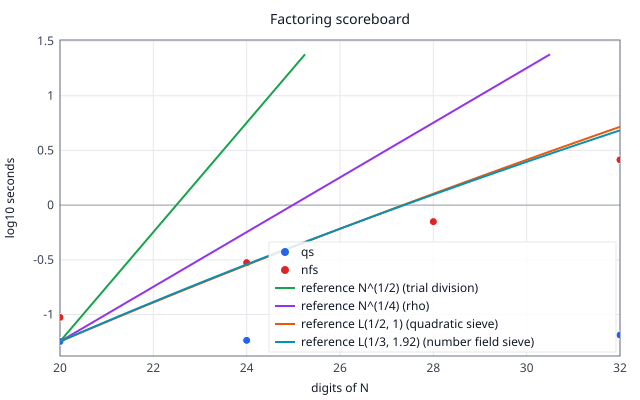

> `scoreplot`: Plots scoreboard results: log10 of the cost against the number of digits, one series of points per method, plus reference curves for N^(1/2), N^(1/4), L(1/2, 1) and L(1/3, 1.92) drawn through the first point (only where they stay near the data).

In [18]:
sb = scoreboard(["qs" "nfs"], 20:4:32, 1, 30)
scoreplot(sb)

(Ignore the fitted growth laws in the scoreboard's explanation: four sizes are too few to tell the laws apart, as it
says itself.) At these sizes the quadratic sieve wins by a factor of about 30. That is not a flaw of the lesson: in serious
programs too, the number field sieve only overtakes the quadratic sieve at around 100 digits. Its extra steps (two
factor bases, characters, the algebraic square root) cost more, and its advantage grows slowly. With this code on a
normal computer:

* the 51-digit part of $2^{193} - 1$ (special form, $x^4 - 8$): about 7 s, quadratic sieve about 2 s;
* the Fermat number $2^{256} + 1$ (78 digits, special form $x^5 + 16$, $m = 2^{52}$): the special number field
  sieve splits it as $1238926361552897$ times a 62-digit prime in under 3 minutes; the quadratic sieve of lesson 6 does not
  finish in 5 minutes.

Record factorizations add what this teaching version leaves out: lattice sieving, two or three large primes per
side, block methods for matrices with millions of rows, and long polynomial searches. RSA-250 took about 2700
core-years.

## Summary

* $X^2 \equiv Y^2 \pmod N$ with $X \not\equiv \pm Y$ gives a factor $\gcd(X - Y, N)$. Squares are built from many
  **smooth** numbers by solving a linear system mod 2 on their exponents.
* Smooth numbers get rare fast as numbers grow, so the size of the numbers that must be smooth decides everything.
* The number field sieve uses $f(m) \equiv 0 \pmod N$ and a root $\alpha$ of $f$: two worlds, joined by
  $\alpha \mapsto m$, that agree modulo $N$. Its numbers $a - bm$ and $F(a, b)$ are about $N^{1/d}$ times small
  factors, far smaller than the quadratic sieve's $\sqrt N$ when $N$ is large.
* A sieve finds pairs where both are smooth; linear algebra mod 2 (with characters) picks a square on both sides;
  square roots and a gcd finish.
* Special forms give tiny polynomials (SNFS); a polynomial that factors gives a factor by algebra alone.
* Commands: `gnfs(N)`, `gnfs(N, f, m)`, `nfspoly(N)`, `polyselect(N, d, generations)`, and `explain = "teach"` for
  step-by-step explanations.

## Exercises

1. **By hand.** $N = 2041$, $\sqrt N \approx 45.2$. Compute `table([x, mod(x^2, N)], x, 46, 52)`, find a set of
   remainders (it may take more than two) whose product is a square, and factor 2041 with a gcd.
2. **Degree.** Run `gnfs(2^128 + 1, x^5 + 4, 2^26)` (degree 5) and compare the work with degrees 3 and 4. Which is
   fastest, and does `nfspoly` predict it?
3. **Reducible polynomials.** Explain what `gnfs(10^40 + 1, x^5 + 1, 10^8)` does (section 6).
4. **The right tool.** (`labrun(method, N)` from lesson 6 runs one method on one number.) Compare `labrun("nfs", 2^128 + 1)` with `labrun("ecm", 2^128 + 1)`. Why does the elliptic
   curve method win here? (How many digits does the smaller factor have?)
5. **Smoothness.** Using `smooth` from section 2, estimate how many of 1000 numbers near $10^{15}$ are 100-smooth.
   What does that say about using the bound 100 for the numbers in section 5?

## Hints and answers

* **Section 1, Try this.** $57^2 \equiv 1600 = 40^2$: $X = 57$, $Y = 40$, $\gcd(57 - 40, 1649) = 17$ and
  $\gcd(57 + 40, 1649) = 97$.
* **Section 2, Try this.** With bound 1000: 266, 41 and 4 of 1000, so seven to fourteen times as many smooth
  numbers. But there are 168 primes up to 1000 against 25 up to 100, so you also need about seven times as many,
  and each one costs more to check. Which bound is best depends on the size of the numbers; real programs choose it
  by experiment.
* **Section 3, Try this.** Zeros at $a \equiv 5$ and $a \equiv 8 \pmod{13}$: $5^2 + 1 = 26$, $8^2 + 1 = 65$.
* **Section 4, Try this.** Usually not: one side or the other has a large prime factor.
* **Step 2 question.** $a^3 + 2 \equiv 0 \pmod 7$ needs a cube equal to $5$ mod 7, but cubes mod 7 are only 0, 1 and 6.
* **Section 7, Try this.** Best degree 3 score 118.1, against 113.2 for degree 4: for 40 digits degree 4 is better.
* **Exercise 1.** The smooth remainders are $46^2 \equiv 75 = 3 \cdot 5^2$, $47^2 \equiv 168 = 2^3 \cdot 3 \cdot 7$,
  $49^2 \equiv 360 = 2^3 \cdot 3^2 \cdot 5$ and $51^2 \equiv 560 = 2^4 \cdot 5 \cdot 7$. Over the primes 2, 3, 5, 7
  their rows mod 2 are $[0\ 1\ 0\ 0]$, $[1\ 1\ 0\ 1]$, $[1\ 0\ 1\ 0]$, $[0\ 0\ 1\ 1]$, and only all four
  together add up to zeros. So $X = 46 \cdot 47 \cdot 49 \cdot 51$, $Y = 2^5 \cdot 3^2 \cdot 5^2 \cdot 7 = 50400$, and
  $\gcd(X - Y, 2041) = 13$, $\gcd(X + Y, 2041) = 157$. (Going on to $x = 59$: $59^2 \equiv 1440$ has the same row
  as 360, so 49 and 59 alone also work.)
* **Exercise 2.** Degree 3 about $1.7 \cdot 10^6$ work units, degree 4 $2.2 \cdot 10^6$, degree 5 $4.1 \cdot 10^6$.
  `nfspoly` predicted that order: scores 92.9, 96.9 and 102.7.
* **Exercise 3.** $x^5 + 1 = (x + 1)(x^4 - x^3 + x^2 - x + 1)$, so $g(m) = 10^8 + 1$ shares a factor with $N$:
  `gnfs` returns $10^8 + 1 = 100000001$ and $N / (10^8 + 1)$ at once. Neither is prime ($10^8 + 1 = 17 \cdot 5882353$),
  which is fine: the method only promised a split.
* **Exercise 4.** The smaller factor, 59649589127497217, has only 17 digits. ECM's cost depends on the size of the
  smallest factor, the sieves' cost on the size of $N$.
* **Exercise 5.** About 1 in 1000, almost none: the sieve in section 5 uses a much larger bound (a few thousand) plus a large prime,
  because its numbers are about $10^{12}$ to $10^{15}$.

## Sources

1. A. K. Lenstra and H. W. Lenstra (eds.), *The Development of the Number Field Sieve*, Lecture Notes in Math. 1554, Springer (1993).
2. J. P. Buhler, H. W. Lenstra and C. Pomerance, "Factoring integers with the number field sieve", in [1], 50–94.
3. C. Pomerance, "A tale of two sieves", *Notices of the AMS* 43 (1996) 1473–1485. The best first reading on both sieves.
4. A. K. Lenstra, H. W. Lenstra, M. S. Manasse and J. M. Pollard, "The factorization of the ninth Fermat number", *Math. Comp.* 61 (1993) 319–349.
5. R. P. Brent and J. M. Pollard, "Factorization of the eighth Fermat number", *Math. Comp.* 36 (1981) 627–630.
6. M. E. Briggs, *An Introduction to the General Number Field Sieve*, master's thesis, Virginia Tech (1998). A gentle, complete walk-through.
7. B. A. Murphy, *Polynomial Selection for the Number Field Sieve Integer Factorisation Algorithm*, PhD thesis, Australian National University (1999).
8. P. L. Montgomery, "Square roots of products of algebraic numbers", *Proc. Symp. Applied Math.* 48 (1994) 567–571; J.-M. Couveignes, "Computing a square root for the number field sieve", in [1], 95–102.
9. F. Boudot, P. Gaudry, A. Guillevic, N. Heninger, E. Thomé and P. Zimmermann, "Comparing the difficulty of factorization and discrete logarithm: a 240-digit experiment", *CRYPTO 2020*; the RSA-250 announcement (2020).
10. R. Crandall and C. Pomerance, *Prime Numbers: A Computational Perspective*, 2nd ed., Springer (2005), section 6.2.
11. T. Kleinjung, "On polynomial selection for the general number field sieve", *Mathematics of Computation* 75 (2006) 2037–2047.
12. S. Bai, C. Bouvier, A. Kruppa and P. Zimmermann, "Better polynomials for GNFS", *Mathematics of Computation* 85 (2016) 861–873.